In [2]:
from ultralytics import YOLO

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
import numpy as np
import pandas as pd
import json

In [29]:
from tqdm import tqdm
import os
from pathlib import Path
from PIL import Image

In [6]:
model_26m = YOLO('yolo26m.pt')

In [44]:
def detectar_fotos(model, carpeta_imgs, carpeta_labels, conf_min=0.1,
                   clase=15, batch=16, salida=None):

    carpeta_imgs, carpeta_labels = Path(carpeta_imgs), Path(carpeta_labels)
    imgs = sorted(carpeta_imgs.glob('*.jpg'))
    filas = []

    for i in tqdm(range(0, len(imgs), batch)):
        lote = imgs[i:i + batch]
        res = model.predict(source=[str(p) for p in lote], conf=conf_min,
                            classes=[clase], device=0, verbose=False, save=False)
        for p, r in zip(lote, res):
            txt = carpeta_labels / (p.stem + '.txt')
            n_real = 0
            if txt.exists():
                n_real = sum(1 for l in txt.read_text().splitlines()
                             if l.split() and l.split()[0] == str(clase))
            filas.append({'foto': p.name,
                          'n_real': n_real,
                          'confs': r.boxes.conf.cpu().numpy().tolist()})

    df = pd.DataFrame(filas)
    if salida:
        df.to_pickle(salida)  
    return df


In [45]:
df_det_coco = detectar_fotos(
    model_26m,
    carpeta_imgs=r'../data/external/val2017/images',
    carpeta_labels=r'../data/external/val2017/labels',
    conf_min=0.10,
    salida=r'../outputs/detector/det_coco_yolo26m.pkl'
)

100%|██████████| 313/313 [16:39<00:00,  3.19s/it]


In [54]:
def evaluar_umbrales(df, umbrales=(0.10, 0.25, 0.40, 0.50, 0.70)):
    hay_gato = df['n_real'] >= 1
    filas = []

    for t in tqdm(umbrales, total=len(umbrales)):
        n_det = df['confs'].apply(lambda c: sum(x >= t for x in c))
        pred = n_det >= 1

        tp = int((pred & hay_gato).sum())
        fp = int((pred & ~hay_gato).sum())
        fn = int((~pred & hay_gato).sum())
        tn = int((~pred & ~hay_gato).sum())

        precision = tp / (tp + fp) if (tp + fp) else 0
        recall = tp / (tp + fn) if (tp + fn) else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0

        filas.append({'conf': t, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
                      'precision': round(precision, 3),
                      'recall': round(recall, 3),
                      'f1': round(f1, 3),
                      'fotos_0_gatos': int((n_det == 0).sum()),
                      'fotos_1_gato': int((n_det == 1).sum()),
                      'fotos_2_o_mas': int((n_det >= 2).sum())})

    return pd.DataFrame(filas)

In [57]:
tabla_eval_coco = evaluar_umbrales(df_det_coco) 
tabla_eval_coco.to_csv(r'../outputs/detector/umbrales_coco_yolo26m.csv', index=False)
tabla_eval_coco

100%|██████████| 5/5 [00:00<00:00, 318.66it/s]


,conf,TP,FP,FN,TN,precision,recall,f1,fotos_0_gatos,fotos_1_gato,fotos_2_o_mas
0,0.10,177,11,7,4805,0.941,0.962,0.952,4812,154,34
1,0.25,173,4,11,4812,0.977,0.940,0.958,4823,155,22
2,0.40,169,2,15,4814,0.988,0.918,0.952,4829,154,17
3,0.50,166,2,18,4814,0.988,0.902,0.943,4832,151,17
4,0.70,155,0,29,4816,1.000,0.842,0.914,4845,142,13


In [62]:
metrics_coco_val = model_26m.val(
        data='../data/external/coco.yaml', 
        save=False,
        save_json=True,
        conf=0.25,
        classes=[15],
        device=0, 
        verbose=False,
        plots=True
    )

Ultralytics 8.4.176  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 646.5±152.8 MB/s, size: 150.8 KB)
val: Scanning C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\external\val2017\labels.cache... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 98% ━━━━━━━━━━━╸ 308/313 2.8s/it 11:36<13.9s


KeyboardInterrupt: 

In [58]:
np.save("../outputs/detector/cm_coco.npy", metrics_coco_val.confusion_matrix.matrix)
np.save("../outputs/detector/ap_coco_por_clase.npy", metrics_coco_val.box.maps)
with open("../outputs/detector/metricas_coco.json", "w") as f:
    json.dump(metrics_coco_val.results_dict, f, indent=2)

In [59]:
print("mAP50-95:", metrics_coco_val.box.map, "| mAP50:", metrics_coco_val.box.map50)
print("AP del gato:", metrics_coco_val.box.maps[15])

mAP50-95: 0.7983186002896514 | mAP50: 0.9398673988838038
AP del gato: 0.7983186002896514


In [60]:
cm_coco_val = np.load("../outputs/detector/cm_coco.npy")
maps_coco_val = np.load("../outputs/detector/ap_coco_por_clase.npy")
with open("../outputs/detector/metricas_coco.json") as f:
    res_coco_val = json.load(f)

**VALIDACIÓN MUESTRA 300**

In [10]:
metrics_muestra_300 = model_26m.val(
    data="../data/external/muestra_300.yaml", 
    conf=0.25,
    save=False,
    device='cpu', 
    verbose=False,
    plots=True
)

Ultralytics 8.4.176  Python-3.12.10 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-12450H)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 33.7±31.9 MB/s, size: 221.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\external\muestra_300... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 345.1it/s 0.9s0.1s
val: New cache created: C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\external\muestra_300.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.9s/it 1:325.3sss
                   all        300        307       0.99      0.983      0.983      0.844
Speed: 0.7ms preprocess, 294.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to

In [ ]:
df_det_coco = detectar_fotos(
    model_26m,
    carpeta_imgs=r'../data/external/muestra_300/images',
    carpeta_labels=r'../data/external/muestra_300/labels',
    conf_min=0.10,
    salida=r'../outputs/detector/det_muestra_300_yolo26m.pkl'
)

In [ ]:
tabla_eval_coco = evaluar_umbrales(df_det_coco) 
tabla_eval_coco.to_csv(r'./outputs/detector/umbrales_muestra_300_yolo26m.csv', index=False)
tabla_eval_coco

In [ ]:
np.save("../outputs/detector/cm_muestra_300.npy", metrics_muestra_300.confusion_matrix.matrix)
np.save("../outputs/detector/ap_por_clase_muestra_300.npy", metrics_muestra_300.box.maps)
with open("../outputs/detector/metricas_muestra_300.json", "w") as f:
    json.dump(metrics_muestra_300.results_dict, f, indent=2)

NameError: name 'metrics_muestra_300' is not defined

In [12]:
print("mAP50-95:", metrics_muestra_300.box.map, "| mAP50:", metrics_muestra_300.box.map50)
print("AP del gato:", metrics_muestra_300.box.maps[15])

mAP50-95: 0.8438700693969337 | mAP50: 0.9830114704375188
AP del gato: 0.8438700693969337


In [13]:
cm_muestra_300 = np.load("../outputs/detector/cm_muestra_300.npy")
maps_muestra_300 = np.load("../outputs/detector/ap_por_clase_muestra_300.npy")
with open("../outputs/detector/metricas_muestra_300.json") as f:
    res = json.load(f)

**ANALISIS RECORTE IMAGENES REID**

In [2]:
df_reid = pd.read_csv('../data/processed/df_cat_reid.csv')
df_reid_modified = df_reid.copy()

In [3]:
len(df_reid_modified)

13106

In [8]:
df_reid_modified.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54


In [9]:
rutas = df_reid_modified['file_path'].astype(str).tolist()
PROC_DET = str("../data/interim/")
LABELS_DET = "det_26m"
lote = 32

In [ ]:
for r in tqdm(range(0, len(rutas), lote)): 
    results_test_crop = model_26m.predict(
    source=rutas[r:r+lote], save=False, save_txt=True, save_conf=True, 
    classes=[15], exist_ok=True, conf=0.25,
    verbose=False, project=PROC_DET, name=LABELS_DET,
)

In [11]:
ids = list(set(df_reid_modified['dir_name']))
ids_int = set(df_reid_modified['dir_name'].astype(int))
miss_ids = sorted(set(range(1, len(ids) + 1)) - ids_int)

In [12]:
miss_ids

[32, 70, 74, 116, 118, 119, 192]

In [13]:
PATH_LABELS = "./runs/data/interim/det_26m/labels"
labels = [os.path.basename(f).split('.')[0] for f in os.scandir(PATH_LABELS) if os.path.basename(f).endswith('txt')]
cat_images = df_reid_modified['file_name'].tolist()

In [14]:
df_analysis = df_reid_modified.copy()

df_analysis['detected'] = df_analysis['file_name'].isin(labels).astype(int)

In [15]:
for id in tqdm(labels):
    file_name = f'{id}.txt'
    file_path = f'{PATH_LABELS}/{file_name}'
    try: 
        data = np.loadtxt(file_path)

        if data.size > 0:
            if data.ndim == 1:
                conf_prediction = data[-1]
            else:
                conf_prediction = 0.0
        else:
            conf_prediction = 0.0
    except Exception:
        conf_prediction = 0.0
    df_analysis.loc[df_analysis['file_name'] == id, 'conf'] = conf_prediction

100%|██████████| 12872/12872 [00:17<00:00, 723.34it/s]


In [16]:
df_analysis.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness,detected,conf
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44,1,0.938555
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42,1,0.956232
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99,1,0.941404
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14,1,0.935295
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54,1,0.928888


In [ ]:
df_analysis_to_save = df_analysis.loc[
    df_analysis['detected'] == 1, ['file_path', 'dir_name', 'file_name']]
df_analysis_to_save.to_csv(
    '../data/processed/df_cat_reid_validation.csv', index=False
)

In [5]:
df_analysis = pd.read_csv('../data/processed/df_cat_reid_validation.csv')
len(df_analysis)

12872

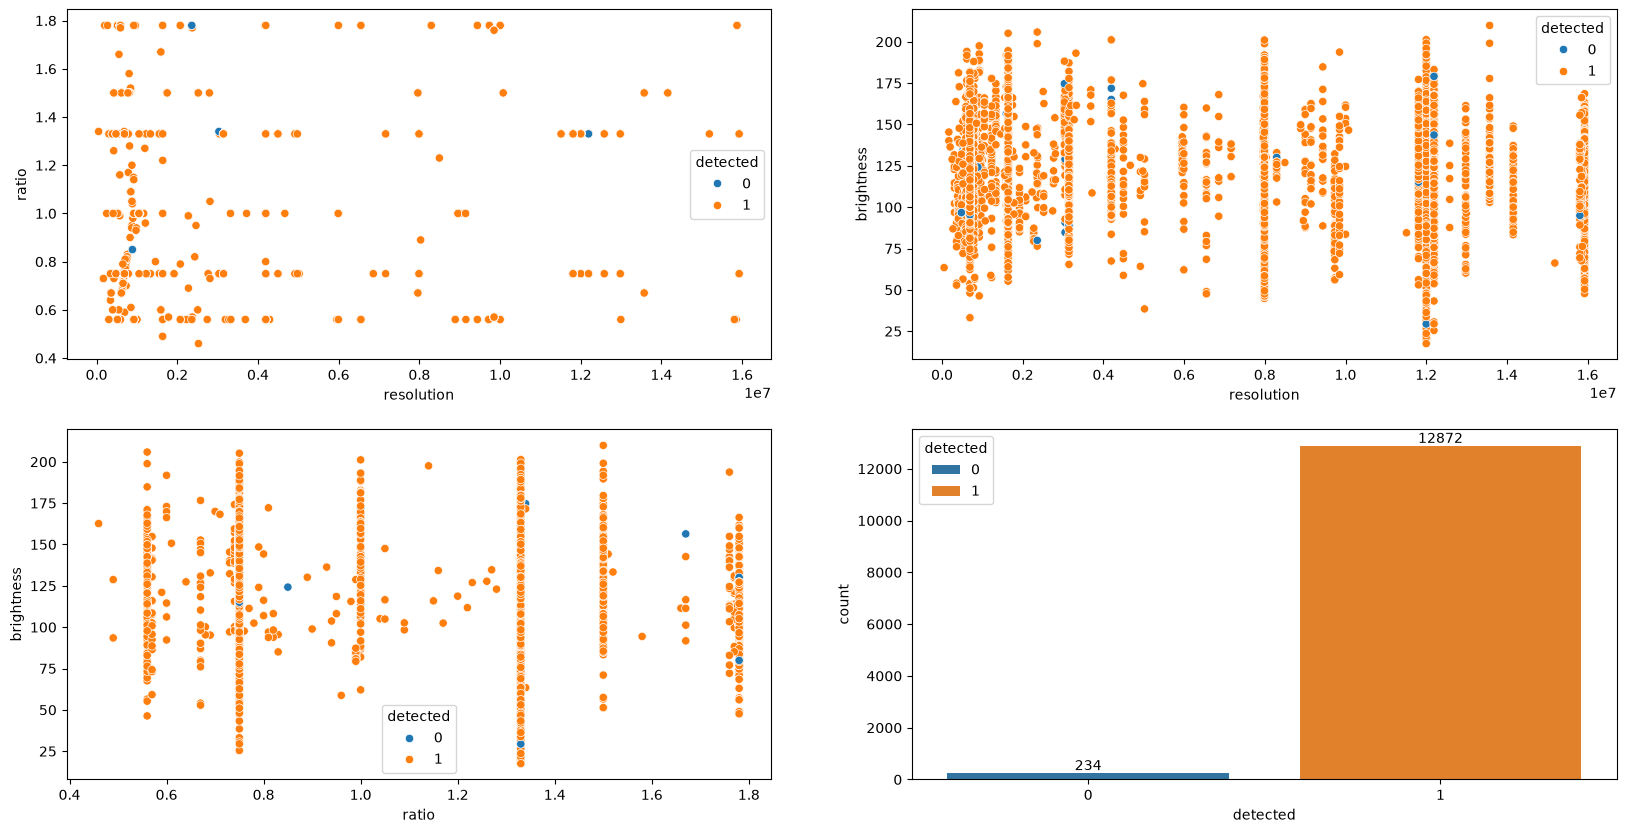

In [108]:
plt.figure(figsize=(20, 10))
plt.subplot(2, 2, 1)

sns.scatterplot(
    data=df_analysis, x='resolution', y='ratio',
    hue='detected', alpha=1)

plt.subplot(2, 2, 2)
sns.scatterplot(
    data=df_analysis, x='resolution', y='brightness',
    hue='detected', alpha=1)

plt.subplot(2, 2, 3)
sns.scatterplot(
    data=df_analysis, x='ratio', y='brightness',
    hue='detected', alpha=1)

plt.subplot(2, 2, 4)
ax = sns.countplot(
    data=df_analysis, x='detected',
    hue='detected', alpha=1)

for container in ax.containers:
    ax.bar_label(container, fontsize=10)
plt.show()